# TP-2 — TinyGPT: instruction tuning and LoRA

**Student: Christian Conchari**

You will take the TinyGPT you pretrained in TP-1 and teach it to follow instructions, then
fine-tune it in two directions.

## From pretraining to fine-tuning

TP-1 left you a model that continues Shakespeare. It cannot follow an instruction, because
nothing in its training data ever looked like one. Pretraining and fine-tuning run the same
loss on the same architecture; four things change:

| | Pretraining | Fine-tuning |
|---|---|---|
| Data | raw text, billions of tokens | curated pairs, thousands |
| Loss | every token | **response tokens only** |
| Learning rate | high | 1-2 orders of magnitude lower |
| Format | none | a template with special tokens |

This is the supervised fine-tuning (SFT) stage behind instruction-following models like:
- InstructGPT / ChatGPT
- Llama-2-Chat
- Alpaca, and the many LoRA adapters built on open models

**Part 1 — Supervised fine-tuning.** Build an instruction dataset, wrap it in a chat
template, and fine-tune every parameter. The supervised loss sees the answer only.

**Part 2 — Parameter-efficient fine-tuning.** Replace full fine-tuning with **LoRA**, and
measure what each fine-tune cost the model in what it already knew.

The base model is TP-1's and does not change: every task fine-tunes a copy of it.

## Tasks

**Part 1**
- Task I — build the SFT dataset with **prompt loss masking**.
- Task II — full fine-tuning, and evaluation.

**Part 2**
- Task III — implement **LoRA** from scratch and compare it against full fine-tuning.
- Task IV — measure **catastrophic forgetting** on the pretraining distribution.

**Then**
- Task V — port your TP-1 `generateV2` into a **chat** function.
- Task VI — read the **attention** at the answer position.
- *Optional* — show that pretraining bought you something.

## How to work on this

**Prerequisites:** TP-1 including **Task X (a real tokenizer)** — this notebook loads
`./checkpoints/tp1_subword/checkpoint_final.pt`, and pretrains its own base model if that
is missing.

Task I ships with a `check_dataset()` cell, and the LoRA cell asserts that the adapted
model starts identical to the base. Run them before training — they cost seconds and catch
the bugs that would otherwise show up as a flat loss curve after the whole fine-tune.

**Keep `./checkpoints/`.** TP-3 continues from the model you fine-tune here rather than
training a new one. You do not hand the checkpoints in — but if you delete them, you will
have to retrain.

References: [LoRA](https://arxiv.org/abs/2106.09685) ·
[InstructGPT](https://arxiv.org/abs/2203.02155) · [PEFT](https://huggingface.co/docs/peft)

In [1]:
import copy
import math
import os
import random
import re
from collections import Counter
from typing import Dict, List, Optional, Tuple

from transformers import AutoTokenizer

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR, StepLR
from torch.utils.data import DataLoader, Dataset

from tinygpt import (
    CharDataset,
    GPTConfig,
    TinyGPT,
    count_parameters,
    describe,
    generate,
    get_device,
    load_checkpoint,
    load_tinyshakespeare,
    plot_losses,
    run_training,
    trim_kv_cache,
)
from trainer import Trainer

torch.manual_seed(1337)
random.seed(1337)

device = get_device()
print(f"device: {device}")

device: cuda


# Stage 0 — the pretrained base model

Same corpus, same tokenizer and same config as TP-1, so the TP-1 checkpoint drops straight in.

In [2]:
PRETRAIN_CHARS = 100_000    # exactly what TP-1 pretrained on -- fixed, so Task IV stays comparable
NUM_WORKERS = 0
TP1_CKPT = "./checkpoints/tp1_subword/checkpoint_final.pt"

# The base model is TP-1's and does not change: same architecture, same tokenizer, same
# 100k characters. The one thing this notebook *can* scale is the fine-tune, so the
# instruction words are mined from the whole corpus while the language-modelling data
# stays the slice the checkpoint was actually trained on.
sft_text = load_tinyshakespeare(None)
text = sft_text[:PRETRAIN_CHARS]

# The same tokenizer TP-1 Task X pretrained with, so its checkpoint drops straight in.
tokenizer = AutoTokenizer.from_pretrained("gpt2")
base_vocab_size = len(tokenizer)

# tie_weights=False: the TP-1 checkpoints keep token_emb and head as two separate
# matrices. load_checkpoint refuses to load those into a tied model rather than
# silently dropping one of them.
config = GPTConfig(vocab_size=base_vocab_size, tie_weights=False)
data = torch.tensor(tokenizer(text, add_special_tokens=False)["input_ids"], dtype=torch.long)
split = int(0.9 * len(data))

# Kept around for Task IV: the pretraining distribution we will check for forgetting.
shakespeare_val_loader = DataLoader(CharDataset(data[split:], config.block_size),
                                   batch_size=config.batch_size, shuffle=False,
                                   drop_last=True, num_workers=NUM_WORKERS)

print(config)
print(f"pretraining slice  {len(text):>9,} chars -> {len(data):,} tokens "
      f"({len(text) / len(data):.2f} chars/token)")
print(f"SFT word corpus    {len(sft_text):>9,} chars")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (30645 > 1024). Running this sequence through the model will result in indexing errors


GPTConfig(block_size=32, batch_size=64, n_embd=64, n_head=4, n_layer=2, dropout=0.1, vocab_size=50257, bias=True, tie_weights=False, ff_class=None, moe_args=None)
pretraining slice    100,000 chars -> 30,645 tokens (3.26 chars/token)
SFT word corpus    1,115,394 chars


In [4]:
base_model = TinyGPT(config).to(device)

if os.path.exists(TP1_CKPT):
    # load_checkpoint tolerates the "_orig_mod." prefix a torch.compile'd CUDA run leaves
    # on every key.
    load_checkpoint(base_model, TP1_CKPT, map_location=device)
    print(f"loaded pretrained weights from {TP1_CKPT}")
else:
    print("no TP-1 Task X checkpoint found, pretraining from scratch")
    print("(run TP-1 Task X first if you want the exact same base model)")
    pretrain_loader = DataLoader(CharDataset(data[:split], config.block_size),
                                 batch_size=config.batch_size, shuffle=True,
                                 drop_last=True, num_workers=NUM_WORKERS)
    opt = AdamW(base_model.parameters(), lr=1e-3)
    trainer = Trainer(model=base_model, train_data_loader=pretrain_loader,
                      test_data_loader=shakespeare_val_loader,
                      loss_fn=torch.nn.CrossEntropyLoss(), gradient_accumulation_steps=1,
                      optimizer=opt, scheduler=StepLR(opt, step_size=100, gamma=0.9),
                      device=device, save_dir="./checkpoints/tp2_base", save_every_n=500)
    run_training(trainer, epochs=2)

describe(base_model, "base model")

loaded pretrained weights from ./checkpoints/tp1_subword/checkpoint_final.pt
base model: 6,535,040 parameters | 6,535,040 trainable (100.00%)


## What this stands in for

The method is the real one; the scale and the data are not.

| | this notebook | a real pipeline |
|---|---|---|
| pretraining | 100k characters of one playwright | 10^12+ tokens, months of GPU time |
| SFT data | ~29k pairs from one corpus | 10^4–10^6 curated pairs, often human-written |
| stages | pretrain → SFT | pretrain → SFT → preference tuning (RLHF / DPO / GRPO) |
| evaluation | exact match + conditioning | benchmark suites, human preference, LLM-as-judge |

Identical at both scales: the loss, prompt masking, the embedding resize, the LoRA
factorisation, and the forgetting trade-off. Those are the transferable parts.

**Set your expectations.** 6.5M parameters pretrained on 30,645 tokens will not write good
Shakespeare — `continue` returns things like `",\nAnd I'll be not, and I am,"`. That is the
correct outcome at this scale, not a mistake you made. Judge the run by the metrics — does
the output depend on the prompt, does `who_said` beat its 3.5% baseline — and read the
samples for mechanism, not for quality.

# The instruction dataset

Three instructions sharing one chat template, chosen to differ in **kind**:

| task | kind | answer | can this model do it? |
|---|---|---|---|
| `continue` | generative | the next ~12 tokens of the corpus | **yes** — the pretraining objective wearing a template |
| `who_said` | classification | a speaker's name | maybe — 98 classes, 3.5% majority baseline |
| `reverse` | string transform | the word backwards | **no**, and provably so |

Mixing a task the model can do with one it cannot is deliberate: when everything scores
zero you cannot tell a hard task from a broken notebook. With `continue` working, a zero
on `reverse` *means* something.

`continue` ships in four phrasings — `continue:`, `go on:`, `what comes next:`,
`finish this:` — and the last is **held out of training**. A model that memorised four
strings fails on it; one that learned "this is a continuation request" does not.

Everything is mined from the whole 1.1M-character corpus, not the 100k slice the base
model saw. The base model is TP-1's and does not change, so the instruction data is the
only lever this notebook has.

## What the tokenizer does to `reverse`

Under byte-level BPE the transform is **not position-local**:

| word | tokens | reversed | tokens |
|---|---|---|---|
| `sword` | `['sword']` | `drows` | `['d', 'rows']` |
| `citizen` | `['c', 'itizen']` | `nezitic` | `['ne', 'z', 'itic']` |
| `hamlet` | `['ham', 'let']` | `telmah` | `['tel', 'm', 'ah']` |

Only ~2 words in 10 keep their token count, and reversed English is close to a random byte
string, so BPE shreds it — 2.00 characters per token against 3.31 for the input. The model
must map one token sequence onto a differently-segmented one, inferring the segmentation
of an output it has not produced yet.

**This is why production LLMs are bad at character-level work** — counting letters,
reversing strings, spelling backwards. The information is there in principle, but the
tokenizer threw away the alignment that would make it easy.

A near-zero score on `reverse` is therefore the correct result. What matters is that you
can explain it — and say why `continue`, in the same template with the same loss and the
same optimizer, does not suffer from it.

In [5]:
USER, ASSISTANT, END, PAD = "<|user|>", "<|assistant|>", "<|end|>", "<|pad|>"

# Three instructions sharing one template, deliberately different in kind:
#
#   continue  generative, and it rides the distribution TP-1 already pretrained on, so it
#             is the one the model can actually do. Four phrasings, so the model has to
#             generalise over *how* it was asked rather than memorise one string.
#   who_said  classification. The answer is a speaker name, so exact match is meaningful
#             and there is a real chance level (~3.5%) to beat. Fluent-sounding output
#             cannot fake this one.
#   reverse   a control that the tokenizer makes impossible -- see the segmentation note
#             above. It is here to fail, and to be explained.
#
# A task set that mixes "can do" with "provably cannot" is the point: with every task
# failing you cannot tell a hard task from a broken notebook.

CONTINUE_PHRASINGS = ["continue:", "go on:", "what comes next:", "finish this:"]
HELD_OUT_PHRASING = "finish this:"      # never seen in training -- see the Task II questions

Example = Tuple[str, str, str]          # (task, user text, answer text)


def format_example(ex: Example) -> Tuple[str, str]:
    """Returns (prompt, answer). The answer carries the END token; the prompt does not."""
    _, body, answer = ex
    return f"{USER}{body}{ASSISTANT}", f"{answer}{END}"


def build_continue(ids: List[int], n_prefix: int = 12, n_answer: int = 12,
                   phrasings=None) -> List[Example]:
    """Non-overlapping (prefix -> continuation) slices of the corpus, wrapped in the template."""
    phrasings = phrasings or CONTINUE_PHRASINGS
    step, out = n_prefix + n_answer, []
    for i in range(0, len(ids) - step, step):
        prefix = tokenizer.decode(ids[i:i + n_prefix])
        answer = tokenizer.decode(ids[i + n_prefix:i + step])
        out.append(("continue", f"{random.choice(phrasings)} {prefix}", answer))
    return out


def build_who_said(pairs: List[Tuple[str, str]], budget: int) -> List[Example]:
    """(speaker, speech) -> ask who spoke. The line is truncated to whatever fits."""
    out = []
    for speaker, speech in pairs:
        line = " ".join(speech.split())
        room = budget - len(tokenizer.encode(f"{USER}who said: {ASSISTANT}")) \
                      - len(tokenizer.encode(speaker + END))
        if room < 5:
            continue
        out.append(("who_said", f"who said: {tokenizer.decode(tokenizer.encode(line)[:room])}",
                    speaker))
    return out


def build_reverse(words: List[str]) -> List[Example]:
    return [("reverse", f"reverse: {w}", w[::-1]) for w in words]


# ---- sources -------------------------------------------------------------------------
sft_ids = tokenizer(sft_text, add_special_tokens=False)["input_ids"]

speeches = re.findall(r"^([A-Z][A-Za-z' ]{1,30}):\n((?:.+\n)+)", sft_text, flags=re.M)
speaker_counts = Counter(s for s, _ in speeches)
speeches = [(s, t) for s, t in speeches if speaker_counts[s] >= 20]   # 98 speakers

words = sorted({w for w in re.findall(r"[A-Za-z]+", sft_text) if 3 <= len(w) <= 10})

# ---- split each source before building, so nothing leaks across the split -------------
BUDGET = config.block_size + 1
cut_ids, cut_sp, cut_w = int(.9 * len(sft_ids)), int(.9 * len(speeches)), int(.9 * len(words))
random.shuffle(speeches)
random.shuffle(words)

# The held-out phrasing never appears in training: Task II asks whether the model
# generalises over instruction wording or memorised the four strings.
train_phrasings = [p for p in CONTINUE_PHRASINGS if p != HELD_OUT_PHRASING]

train_examples = (build_continue(sft_ids[:cut_ids], phrasings=train_phrasings)
                  + build_who_said(speeches[:cut_sp], BUDGET)
                  + build_reverse(words[:cut_w]))
val_examples = (build_continue(sft_ids[cut_ids:])
                + build_who_said(speeches[cut_sp:], BUDGET)
                + build_reverse(words[cut_w:]))
random.shuffle(train_examples)
random.shuffle(val_examples)

TASKS = ("continue", "who_said", "reverse")
print(f"{len(train_examples):,} train | {len(val_examples):,} val")
for t in TASKS:
    n_tr = sum(1 for e in train_examples if e[0] == t)
    n_va = sum(1 for e in val_examples if e[0] == t)
    print(f"   {t:<9} {n_tr:>7,} train  {n_va:>6,} val")

print("\none of each:")
for t in TASKS:
    ex = next(e for e in train_examples if e[0] == t)
    print(f"   {''.join(format_example(ex))!r}")

# What the tokenizer does to `reverse`: the transform is not position-local.
print()
for w in ("sword", "citizen", "hamlet"):
    seg = lambda s: [tokenizer.decode([i]) for i in tokenizer.encode(s)]
    print(f"{w:<9} {str(seg(w)):<24} -> reverse {seg(w[::-1])}")


29,381 train | 3,266 val
   continue   12,675 train   1,408 val
   who_said    5,365 train     597 val
   reverse    11,341 train   1,261 val

one of each:
   '<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>:\nHere in the prison, father,\nThere died<|end|>'
   "<|user|>who said: Go, nurse, go with her: we'll to<|assistant|>CAPULET<|end|>"
   '<|user|>reverse: distressed<|assistant|>dessertsid<|end|>'

sword     ['sword']                -> reverse ['d', 'rows']
citizen   ['c', 'itizen']          -> reverse ['ne', 'z', 'itic']
hamlet    ['ham', 'let']           -> reverse ['tel', 'm', 'ah']


## Special tokens and embedding resize

The four template markers are not characters, so the pretrained vocabulary has no ids
for them. Appending them keeps every learned id stable, and
`resize_token_embeddings` grows the embedding matrix and the output head while
preserving every pretrained row. The new rows start random — remember that for Task III.

In [6]:
special_ids = tokenizer.add_special_tokens(
    {"additional_special_tokens": [USER, ASSISTANT, END, PAD]})
PAD_ID = tokenizer.convert_tokens_to_ids(PAD)
END_ID = tokenizer.convert_tokens_to_ids(END)

base_model.resize_token_embeddings(len(tokenizer))

print(f"vocab {base_vocab_size:,} -> {len(tokenizer):,} (+{special_ids} reserved ids)")
describe(base_model, "base model (resized)")

demo = "".join(format_example(train_examples[0]))
print(repr(demo))
print("->", tokenizer.encode(demo), [tokenizer.decode([i]) for i in tokenizer.encode(demo)])


vocab 50,257 -> 50,261 (+4 reserved ids)
base model (resized): 6,535,552 parameters | 6,535,552 trainable (100.00%)
'<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>:\nHere in the prison, father,\nThere died<|end|>'
-> [50257, 43043, 25, 220, 2000, 339, 318, 198, 35653, 12270, 540, 13, 198, 198, 15946, 455, 50258, 25, 198, 4342, 287, 262, 3770, 11, 2988, 11, 198, 1858, 3724, 50259] ['<|user|>', 'continue', ':', ' ', ' mind', ' he', ' is', '\n', 'Were', ' damn', 'able', '.', '\n', '\n', 'Prov', 'ost', '<|assistant|>', ':', '\n', 'Here', ' in', ' the', ' prison', ',', ' father', ',', '\n', 'There', ' died', '<|end|>']


# Task I — the SFT dataset and prompt loss masking

The single most important difference between pretraining and supervised fine-tuning:
**the supervised loss is computed on the response only.** Training the model to predict
the prompt teaches it to generate instructions, and it drowns the signal you want in
tokens the user will always supply.

## The objective, following GPT-1

Radford et al. (2018), §3.3, write fine-tuning as a supervised term plus the pretraining
term carried along:

$$L_2(\mathcal{C}) = \sum_{(x,y)} \log P(y \mid x^1, \dots, x^m)$$

$$L_3(\mathcal{C}) = L_2(\mathcal{C}) + \lambda \, L_1(\mathcal{C})$$

$L_2$ is cross-entropy on the **answer tokens only** — exactly what prompt masking
produces. $L_1$ is ordinary language modelling over the same sequences: predict **every**
token, prompt included. The paper reports that keeping $L_1$ in the mix *"improved
generalization"* and *"accelerated convergence"*. Here it does something else as well: it
keeps the model a language model at all.

Both terms are read off **one** label row. $L_2$'s targets are a strict subset of $L_1$'s
with the same token values — only the positions differ — so a single row suffices if each
entry records which objectives claim it:

| entry | position | claimed by |
|---|---|---|
| `-100` | padding | neither |
| `id` | prompt token | $L_1$ |
| `id + ANSWER_OFFSET` | answer token | $L_1$ **and** $L_2$ |

Two rows would read better, but `Trainer` flattens targets with `.view(B * T)`, which
asserts the size — widening it means editing `trainer.py`, which TP-1 also imports.

**Recipe**

1. `prompt, answer = format_example(ex)` — `ex` is a `(task, user text, answer)` triple.
2. `prompt_ids = tokenizer.encode(prompt)`, `answer_ids = tokenizer.encode(answer)`,
   `full = prompt_ids + answer_ids`.
3. `labels = prompt_ids + [i + ANSWER_OFFSET for i in answer_ids]`, same length as `full`.
4. Pad `full` with `PAD_ID` and `labels` with `IGNORE`, up to `block_size + 1`.
5. `x = full[:-1]`, `y = labels[1:]`. Both `torch.long`, both `(block_size,)`.

**Why the shift.** The model at position `t` predicts token `t + 1`, so the target for
`x[t]` is `labels[t + 1]`. Get it backwards and the model learns to copy its input — the
loss drops and the generations are garbage.

In [7]:
IGNORE_INDEX = -100
# Answer targets are stored as `token_id + ANSWER_OFFSET` so that one label row can say
# which objectives claim each position. See InstructionDataset below.
ANSWER_OFFSET = len(tokenizer)


class InstructionDataset(Dataset):
    """
    Supervised fine-tuning dataset with prompt loss masking.
    """

    def __init__(self, examples: List[Tuple[str, str]], tokenizer,
                 block_size: int, pad_id: int, ignore_index: int = IGNORE_INDEX):
        self.examples = examples
        self.tokenizer = tokenizer
        self.block_size = block_size
        self.pad_id = pad_id
        self.ignore_index = ignore_index

    def __len__(self) -> int:
        return len(self.examples)

    def __getitem__(self, idx: int):
        prompt, answer = format_example(self.examples[idx])
        prompt_ids = self.tokenizer.encode(prompt)
        answer_ids = self.tokenizer.encode(answer)

        full = prompt_ids + answer_ids
        # prompt tokens feed L1 only, answer tokens are offset so they feed L1 and L2
        labels = prompt_ids + [i + ANSWER_OFFSET for i in answer_ids]

        # one extra position, consumed by the shift
        size = self.block_size + 1
        full, labels = full[:size], labels[:size]
        pad = size - len(full)
        full = full + [self.pad_id] * pad
        labels = labels + [self.ignore_index] * pad

        x = torch.tensor(full[:-1], dtype=torch.long)
        y = torch.tensor(labels[1:], dtype=torch.long)
        return x, y

## Self-check

In [8]:
def check_dataset():
    ds = InstructionDataset(train_examples, tokenizer, config.block_size, PAD_ID)
    x, y = ds[0]

    assert x.shape == (config.block_size,), f"x: {x.shape}"
    assert y.shape == (config.block_size,), f"y: {y.shape}"
    assert x.dtype == torch.long and y.dtype == torch.long

    prompt, answer = format_example(ds.examples[0])

    # decode the row the same way the loss does
    is_answer = y >= ANSWER_OFFSET
    lm_row = torch.where(is_answer, y - ANSWER_OFFSET, y)
    sft_row = torch.where(is_answer, lm_row, torch.full_like(y, IGNORE_INDEX))

    # L1 supervises the prompt as well as the answer, so it must cover strictly more
    assert int((lm_row != IGNORE_INDEX).sum()) > int((sft_row != IGNORE_INDEX).sum()), \
        "the L1 row must supervise more positions than the L2 row"
    # and neither objective may ever target a pad
    assert not ((x == PAD_ID) & (lm_row != IGNORE_INDEX)).any(), "padding is being supervised"

    # exactly the answer tokens are supervised by L2
    supervised = (sft_row != IGNORE_INDEX)
    assert int(supervised.sum()) == len(tokenizer.encode(answer)), (
        f"{int(supervised.sum())} != {len(tokenizer.encode(answer))}")

    # and the supervised targets reconstruct the answer
    recovered = tokenizer.decode(sft_row[supervised].tolist())
    assert recovered == answer, f"{recovered!r} != {answer!r}"

    # the shift is right: y[t] is the token that follows x[t]
    t = int(supervised.nonzero()[0])
    full = tokenizer.encode(prompt + answer)
    assert int(x[t]) == full[t] and int(sft_row[t]) == full[t + 1]

    print(f"prompt   {prompt!r}")
    print(f"answer   {answer!r}")
    print(f"x        {tokenizer.decode(x[x != PAD_ID].tolist())!r}")
    print(f"L2 targets  {recovered!r} ({int(supervised.sum())}/{config.block_size} positions)")
    print(f"L1 targets  {int((lm_row != IGNORE_INDEX).sum())}/{config.block_size} positions")
    print("all checks passed")


check_dataset()

prompt   '<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>'
answer   ':\nHere in the prison, father,\nThere died<|end|>'
x        '<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>:\nHere in the prison, father,\nThere died<|end|>'
L2 targets  ':\nHere in the prison, father,\nThere died<|end|>' (13/32 positions)
L1 targets  29/32 positions
all checks passed


## Packing and replay

Two adjustments sit between the dataset and the optimizer. Both are standard practice and
both change the result here, so they are worth understanding before you read the numbers.

**Packing.** One example per 32-token block wastes ~71% of every batch on padding — but
the bigger problem is *where* it leaves the supervision. With one short example per block,
answers only ever appear at positions 4–12; positions 16–31 never receive a single
instruction gradient. A model can then satisfy the training set with a positional shortcut
— *"emit an answer around position 5"* — instead of the rule you want, *"emit an answer
after `<|assistant|>`"*. Both fit the data perfectly; only one survives a longer prompt,
and a chat request with a system prompt or a second turn is exactly that. Concatenating
examples until the block is full removes both problems at once.

**Replay.** GPT-1 computes $L_1$ over the fine-tuning corpus $\mathcal{C}$ itself. Ours is
narrow — one corpus, three instruction types — so $L_1$ alone does little to hold the model
near the distribution TP-1 pretrained it on — which is what Task IV measures. Replay
widens $L_1$'s corpus with raw pretraining text.

Mix it by **supervised positions, not example count**. An instruction example supervises
~4 of 32 positions while a replay example supervises all 32, so one replay item carries
roughly nine instruction items' worth of gradient — counting examples, "25%" would in fact
be 68% of $L_1$.

In [9]:
class PackedInstructionDataset(Dataset):
    """
    Examples concatenated into full blocks instead of one padded example per block.

    Removes both the padding waste and the positional shortcut described above. Caveat:
    without a block-diagonal mask a packed example can attend to the one before it, which
    most implementations accept.
    """

    def __init__(self, examples: List[Tuple[str, str]], tokenizer,
                 block_size: int, pad_id: int, ignore_index: int = IGNORE_INDEX):
        self.block_size, self.pad_id, self.ignore_index = block_size, pad_id, ignore_index
        size = block_size + 1                      # one extra, consumed by the shift
        self.blocks, self.n_supervised = [], 0
        full, labels = [], []

        for ex in examples:
            prompt, answer = format_example(ex)
            p, a = tokenizer.encode(prompt), tokenizer.encode(answer)
            if len(p) + len(a) > size:
                continue                           # cannot fit alone; nothing here does
            if len(full) + len(p) + len(a) > size:
                self.blocks.append(self._pack(full, labels))
                full, labels = [], []
            full += p + a
            labels += p + [i + ANSWER_OFFSET for i in a]
            self.n_supervised += len(a)
        if full:
            self.blocks.append(self._pack(full, labels))

    def _pack(self, full: List[int], labels: List[int]):
        size = self.block_size + 1
        pad = size - len(full)
        full = full + [self.pad_id] * pad
        labels = labels + [self.ignore_index] * pad   # padding is a target in neither
        return (torch.tensor(full[:-1], dtype=torch.long),
                torch.tensor(labels[1:], dtype=torch.long))

    def __len__(self) -> int:
        return len(self.blocks)

    def __getitem__(self, idx: int):
        return self.blocks[idx]


class ReplayDataset(Dataset):
    """
    Instruction examples with a slice of the pretraining corpus mixed back in.

    Replay items are plain next-token prediction, so both kinds of example share one loss
    function and sit in the same batch.
    """

    def __init__(self, sft: Dataset, lm: Dataset, n_replay: int):
        self.sft, self.lm = sft, lm
        self.n_replay = n_replay

    def __len__(self) -> int:
        return len(self.sft) + self.n_replay

    def __getitem__(self, idx: int):
        if idx < len(self.sft):
            return self.sft[idx]
        # No ANSWER_OFFSET on raw labels, so a replay sequence feeds L1 and not L2.
        return self.lm[(idx - len(self.sft)) % len(self.lm)]


class SFTWithAuxLM(nn.Module):
    """
    GPT-1's fine-tuning objective:  L3 = L2 + lambda * L1.

    Both terms come off one forward pass. Each is a per-token mean over its own supervised
    positions, so `lambda` weights comparable quantities; `clamp(min=1)` keeps a batch with
    no answer tokens at 0 instead of NaN.
    """

    def __init__(self, offset: int = ANSWER_OFFSET, lam: float = 0.5,
                 ignore_index: int = IGNORE_INDEX):
        super().__init__()
        self.offset, self.lam, self.ignore_index = offset, lam, ignore_index

    def _per_token(self, logits, targets):
        total = F.cross_entropy(logits, targets,
                                ignore_index=self.ignore_index, reduction="sum")
        return total / (targets != self.ignore_index).sum().clamp(min=1)

    def forward(self, logits, targets):
        # Undo the dataset's encoding. Answer positions were stored offset; everything
        # else is already a plain token id, or -100 for padding.
        is_answer = targets >= self.offset
        lm = torch.where(is_answer, targets - self.offset, targets)
        sft = torch.where(is_answer, lm, torch.full_like(lm, self.ignore_index))
        return self._per_token(logits, sft) + self.lam * self._per_token(logits, lm)


AUX_LM_LAMBDA = 0.5      # the lambda of L3 = L2 + lambda * L1, as in the GPT-1 paper
REPLAY_SHARE = 0.25      # share of L1's corpus drawn from pretraining text, by tokens

sft_train = PackedInstructionDataset(train_examples, tokenizer, config.block_size, PAD_ID)
lm_train = CharDataset(data[:split], config.block_size)

# What packing bought, measured rather than asserted.
_padded = InstructionDataset(train_examples, tokenizer, config.block_size, PAD_ID)
_pad_free = 100 * sft_train.n_supervised / (len(sft_train) * config.block_size)
print(f"padded : {len(_padded):>6,} blocks, "
      f"{100 * sft_train.n_supervised / (len(_padded) * config.block_size):4.1f}% of positions are L2 targets")
print(f"packed : {len(sft_train):>6,} blocks, {_pad_free:4.1f}% -- "
      f"{len(_padded) / len(sft_train):.1f}x fewer blocks for the same supervision\n")

# Mixed by supervised positions, not by example count -- see the note above.
sft_positions = sft_train.n_supervised
n_replay = int(REPLAY_SHARE / (1 - REPLAY_SHARE) * sft_positions / config.block_size)

sft_train_loader = DataLoader(
    ReplayDataset(sft_train, lm_train, n_replay),
    batch_size=config.batch_size, shuffle=True, drop_last=True, num_workers=NUM_WORKERS)
# Validation stays instructions-only and unpacked, so its loss is a clean per-token number.
sft_val_loader = DataLoader(
    InstructionDataset(val_examples, tokenizer, config.block_size, PAD_ID),
    batch_size=config.batch_size, shuffle=False, drop_last=True, num_workers=NUM_WORKERS)

replay_positions = n_replay * config.block_size
print(f"instructions {len(sft_train):>7,} blocks   -> {sft_positions:>9,} L2 targets"
      f"  ({100 * sft_positions / (sft_positions + replay_positions):4.1f}% of L1's corpus)")
print(f"replay       {n_replay:>7,} blocks   -> {replay_positions:>9,} L1 targets"
      f"  ({100 * replay_positions / (sft_positions + replay_positions):4.1f}%)")
print(f"{len(sft_train_loader)} train batches | {len(sft_val_loader)} val batches "
      f"(instructions only)")

padded : 29,381 blocks, 25.5% of positions are L2 targets
packed : 23,216 blocks, 32.2% -- 1.3x fewer blocks for the same supervision

instructions  23,216 blocks   ->   239,587 L2 targets  (75.0% of L1's corpus)
replay         2,495 blocks   ->    79,840 L1 targets  (25.0%)
401 train batches | 51 val batches (instructions only)


# Task II — full fine-tuning

Every parameter is trainable, at a learning rate an order of magnitude below pretraining.
Too high and you erase the pretrained weights before they can be reused — one of the
things Task IV measures.

Evaluation reports exact match on training and held-out examples for the two tasks with a
single right answer, `who_said` and `reverse`. `continue` is generative, so exact match is
meaningless there; it is scored by `continuation_quality` — cross-entropy on the answer
tokens, plus the share of continuations scoring better under **their own** prefix than a
stranger's.

That last number is the one to watch. 50% is chance: fluent Shakespeare with no relation
to what you asked. A generative task can look like a success to the eye and fail this
outright.

The training mix also carries a **replay** fraction of raw Shakespeare (`REPLAY_SHARE`),
because instruction data alone pulls the model off its pretraining distribution hard
enough to stop it being a language model — which is what Task IV measures.

In [10]:
@torch.no_grad()
def generate_until(model, prompt: str, stop_id: int = None, max_new_tokens: int = 24) -> str:
    """Greedy decoding that stops at the END token. Returns only the generated part."""
    model.eval()
    stop_id = END_ID if stop_id is None else stop_id
    dev = next(model.parameters()).device
    idx = torch.tensor(tokenizer.encode(prompt), dtype=torch.long, device=dev)[None, :]
    kv, produced = None, []

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.config.block_size:] if kv is None else idx[:, -1:]
        logits, kv = model(idx_cond, kv_cache=kv, use_cache=True)
        kv = trim_kv_cache(kv, model.config.block_size - 1)
        nxt = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        if int(nxt) == stop_id:
            break
        produced.append(int(nxt))
        idx = torch.cat((idx, nxt), dim=1)

    return tokenizer.decode(produced)


@torch.no_grad()
def answer_loss(model, prompt: str, answer: str) -> float:
    """Cross-entropy on the answer tokens of one (prompt, answer) pair."""
    p, a = tokenizer.encode(prompt), tokenizer.encode(answer)
    ids = (p + a)[: model.config.block_size + 1]
    x = torch.tensor(ids[:-1], device=device)[None, :]
    y = torch.tensor(ids[1:], device=device)[None, :]
    tgt = torch.full_like(y, IGNORE_INDEX)
    tgt[:, len(p) - 1:] = y[:, len(p) - 1:]          # the shift again: x[t] predicts y[t]
    logits = model(x)
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1),
                           ignore_index=IGNORE_INDEX).item()


@torch.no_grad()
def continuation_quality(model, examples, n: int = 120) -> Dict[str, float]:
    """
    `loss` is cross-entropy on the answer tokens, in the same units as the pretraining loss.

    `conditioned` is the share of continuations scoring better under their own prefix than
    under a stranger's. 50% is chance: fluent output that ignores the prompt. A generative
    task can look successful to the eye and still fail this.
    """
    sample = [e for e in examples if e[0] == "continue"][:n]
    if not sample:
        return {}
    losses, wins = [], 0
    for i, ex in enumerate(sample):
        prompt, answer = format_example(ex)
        other_prompt = format_example(sample[(i + 1) % len(sample)])[0]
        own = answer_loss(model, prompt, answer)
        losses.append(own)
        wins += own < answer_loss(model, other_prompt, answer)
    return {"loss": sum(losses) / len(sample), "conditioned": wins / len(sample)}


EXACT_MATCH_TASKS = ("who_said", "reverse")   # `continue` has no single right string


@torch.no_grad()
def show_continuations(model, examples, k: int = 3, max_new_tokens: int = 18) -> None:
    """Read what the generative task actually produces. Not a metric -- a sanity check."""
    for ex in [e for e in examples if e[0] == "continue"][:k]:
        prompt, answer = format_example(ex)
        print(f"   ask  {prompt[len(USER):-len(ASSISTANT)]!r}")
        print(f"   got  {generate_until(model, prompt, max_new_tokens=max_new_tokens)!r}")
        print(f"   true {answer[:-len(END)]!r}")


@torch.no_grad()
def evaluate_instructions(model, examples, n: int = 150, verbose: int = 5) -> Dict[str, float]:
    """Exact match, for the two tasks that have exactly one right string."""
    # `continue` is not decoded: its exact match is 0.0% by construction and the decodes
    # are the most expensive thing here. It is scored by `continuation_quality` instead.
    hits = {t: [0, 0] for t in EXACT_MATCH_TASKS}
    sample = [e for e in examples if e[0] in EXACT_MATCH_TASKS][:n]

    for i, ex in enumerate(sample):
        task = ex[0]
        prompt, answer = format_example(ex)
        expected = answer[: -len(END)]
        got = generate_until(model, prompt, max_new_tokens=14)   # these answers are short
        hits[task][1] += 1
        hits[task][0] += int(got == expected)
        if i < verbose:
            mark = "OK " if got == expected else "XX "
            print(f"   {mark} {task:>8}: {got[:36]!r:<38} want {expected[:26]!r}")

    acc = {t: c / max(k, 1) for t, (c, k) in hits.items()}
    acc["overall"] = sum(c for c, _ in hits.values()) / max(sum(k for _, k in hits.values()), 1)
    print("   " + " | ".join(f"{k}={v:.1%}" for k, v in acc.items()))
    return acc


@torch.no_grad()
def evaluate_both(model, name: str, n: int = 150):
    """Training vs held-out. The gap is memorisation against learning."""
    print(f"### {name}")
    print("  -- exact match, training examples --")
    acc_train = evaluate_instructions(model, train_examples, n=n, verbose=0)
    print("  -- exact match, held-out examples --")
    acc_val = evaluate_instructions(model, val_examples, n=n, verbose=4)
    print(f"  gap: {acc_train['overall'] - acc_val['overall']:+.1%}")
    q = continuation_quality(model, val_examples)
    if q:
        print(f"  -- continue (generative) --")
        print(f"   answer loss {q['loss']:.3f} | prompt-conditioned {q['conditioned']:.1%}"
              f"   (50% = ignoring the prompt)")
        show_continuations(model, val_examples)
    return acc_train, acc_val


In [11]:
print(f"### base model, before fine-tuning")
acc_base = evaluate_instructions(base_model, val_examples, n=60)

### base model, before fine-tuning
   XX  who_said: ',\nAnd,\nAnd the,\nAnd,\nThat,'       want 'QUEEN MARGARET'
   XX   reverse: ',\nAnd, and,\nAnd,\nAnd the, and'     want 'nierehw'
   XX   reverse: ',\nAnd, and,\nAnd,\nAnd the, and'     want 'sedivorp'
   XX   reverse: ',\nAnd, and,\nAnd,\nAnd the, and'     want 'deyd'
   XX  who_said: ',\nAnd,\nAnd,\nAnd, and,\nAnd'        want 'CLIFFORD'
   who_said=0.0% | reverse=0.0% | overall=0.0%


In [12]:
def param_groups(model: nn.Module, weight_decay: float = 0.01):
    """
    Weight decay on the matrices only.

    AdamW decays every parameter in the group each step, including the ~47,000 embedding
    rows a given batch never touched. GPT-2 and nanoGPT both split the groups this way.
    """
    no_decay_prefix = ("token_emb", "pos_emb", "head")
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if p.ndim < 2 or name.startswith(no_decay_prefix) else decay).append(p)
    return [{"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0}]


def cosine_with_warmup(opt, total_steps: int, warmup_frac: float = 0.05):
    """
    Linear warmup, then cosine decay to zero, defined against the whole run.

    Warmup matters because step 0 of a fine-tune pairs a pretrained body with freshly
    random embedding rows; hitting those at full learning rate wrecks the pretrained
    weights. Defining the schedule against `total_steps` rather than a fixed step count
    keeps it meaningful when the dataset size changes.
    """
    warmup = max(1, int(total_steps * warmup_frac))

    def scale(step: int) -> float:
        if step < warmup:
            return (step + 1) / warmup
        progress = (step - warmup) / max(1, total_steps - warmup)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))

    return LambdaLR(opt, scale)


FT_EPOCHS = 10          # ~9 min on an M3 Pro now that the SFT set is 5x bigger
FT_LR = 3e-4
FT_STEPS = FT_EPOCHS * len(sft_train_loader)

full_ft_model = copy.deepcopy(base_model).to(device)
for p in full_ft_model.parameters():
    p.requires_grad_(True)
describe(full_ft_model, "full fine-tuning")

opt = AdamW(param_groups(full_ft_model), lr=FT_LR)
full_trainer = Trainer(
    model=full_ft_model,
    train_data_loader=sft_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt,
    scheduler=cosine_with_warmup(opt, FT_STEPS),
    device=device,
    save_dir="./checkpoints/tp2_full_ft",
    save_every_n=500,
)

history_full = run_training(full_trainer, epochs=FT_EPOCHS)

full fine-tuning: 6,535,552 parameters | 6,535,552 trainable (100.00%)
mixed precision: on (bfloat16)


val_loss 11.25477: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 97.94it/s]


epoch 1/10 | train 10.7983 | val 10.9187


val_loss 9.15864: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 95.68it/s]


epoch 2/10 | train 9.3237 | val 9.3595


...

epoch 8/10 | train 7.6165 | val 7.6134


val_loss 7.20856: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 96.14it/s]


epoch 9/10 | train 7.4343 | val 7.5993


val_loss 7.20560: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 95.99it/s]


epoch 10/10 | train 7.5888 | val 7.5971


In [13]:
acc_full_train, acc_full = evaluate_both(full_ft_model, "after full fine-tuning")

### after full fine-tuning
  -- exact match, training examples --
   who_said=7.1% | reverse=0.0% | overall=2.0%
  -- exact match, held-out examples --
   XX  who_said: 'QUEEN ELIZABETH'                      want 'QUEEN MARGARET'
   XX   reverse: ''                                     want 'nierehw'
   XX   reverse: ''                                     want 'sedivorp'
   XX   reverse: ''                                     want 'deyd'
   who_said=15.1% | reverse=0.0% | overall=5.3%
  gap: -3.3%
  -- continue (generative) --
   answer loss 5.439 | prompt-conditioned 60.0%   (50% = ignoring the prompt)
   ask  'continue:  here you sty me\nIn this hard rock, whiles'
   got  '\nAnd the'
   true " you do keep from me\nThe rest o' the island"
   ask  'go on:  for the mischance of\nthe hour, if it so'
   got  '\nAnd, and the,\nAnd the the'
   true ' hap. Cheerly, good hearts! Out\n'
   ask  'what comes next: , bountiful Fortune,\nNow my dear lady, hath'
   got  '\nAnd, and the,\nAnd the the

### Held-out phrasing

Extra cell for question 5. It splits the validation `continue` examples by phrasing and scores each one against a stranger with the same phrasing, so only the prefix text changes between the two prompts. `finish this:` never appears in training, the other three do. The base model is included as a reference for how hard each group of examples is before fine-tuning.

In [15]:
@torch.no_grad()
def phrasing_breakdown(model, name: str, n_decode: int = 60) -> None:
    """
    `continue` split by phrasing. The stranger shares the phrasing, so only the prefix
    text differs between the two prompts.
    """
    model.eval()                        # answer_loss does not switch dropout off itself
    cont = [e for e in val_examples if e[0] == "continue"]
    print(f"### {name}")
    for ph in CONTINUE_PHRASINGS:
        s = [e for e in cont if e[1].startswith(ph + " ")]
        losses, wins = [], 0
        for i, ex in enumerate(s):
            prompt, answer = format_example(ex)
            other_prompt = format_example(s[(i + 1) % len(s)])[0]
            own = answer_loss(model, prompt, answer)
            losses.append(own)
            wins += own < answer_loss(model, other_prompt, answer)
        stops = sum(len(tokenizer.encode(generate_until(model, format_example(ex)[0]))) < 24
                    for ex in s[:n_decode])
        mark = "  <- held out" if ph == HELD_OUT_PHRASING else ""
        print(f"   {ph:<18} n={len(s):>3} | loss {sum(losses) / len(s):.3f} | "
              f"conditioned {wins / len(s):6.1%} | terminates {stops / n_decode:6.1%}{mark}")


phrasing_breakdown(base_model, "base model")
phrasing_breakdown(full_ft_model, "after full fine-tuning")


### base model
   continue:          n=373 | loss 7.902 | conditioned  58.2% | terminates   0.0%
   go on:             n=367 | loss 8.058 | conditioned  59.9% | terminates   0.0%
   what comes next:   n=328 | loss 8.024 | conditioned  56.7% | terminates   1.7%
   finish this:       n=340 | loss 8.140 | conditioned  54.1% | terminates   1.7%  <- held out
### after full fine-tuning
   continue:          n=373 | loss 5.386 | conditioned  66.5% | terminates 100.0%
   go on:             n=367 | loss 5.410 | conditioned  73.8% | terminates 100.0%
   what comes next:   n=328 | loss 5.289 | conditioned  74.4% | terminates 100.0%
   finish this:       n=340 | loss 5.501 | conditioned  70.9% | terminates 100.0%  <- held out


### Question 6 answer: (c) 10x learning rate

Variant (c). The Task II run again with `FT_LR` raised 10x, on a fresh copy of the base model and saved to its own directory, so the Task II checkpoint stays as it is.

My prediction before running it was that `continue` gets worse because a 10x learning rate moves the pretrained weights it relies on, `who_said` might improve, `reverse` stays at 0%, and the SFT loss falls faster.

In [16]:
torch.manual_seed(1337)
lr10_model = copy.deepcopy(base_model).to(device)
for p in lr10_model.parameters():
    p.requires_grad_(True)

opt_lr10 = AdamW(param_groups(lr10_model), lr=FT_LR * 10)
lr10_trainer = Trainer(
    model=lr10_model,
    train_data_loader=sft_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt_lr10,
    scheduler=cosine_with_warmup(opt_lr10, FT_STEPS),
    device=device,
    save_dir="./checkpoints/tp2_full_ft_lr10",
    save_every_n=500,
)

history_lr10 = run_training(lr10_trainer, epochs=FT_EPOCHS)
evaluate_both(lr10_model, "full fine-tuning, 10x FT_LR")
phrasing_breakdown(lr10_model, "full fine-tuning, 10x FT_LR")


mixed precision: on (bfloat16)


val_loss 6.86823: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 97.30it/s]


epoch 1/10 | train 7.4302 | val 7.2819


val_loss 6.19643: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 98.19it/s]


epoch 2/10 | train 6.7269 | val 6.6095


...

epoch 8/10 | train 5.4493 | val 6.0305


val_loss 5.50664: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 96.34it/s]


epoch 9/10 | train 5.3937 | val 6.0339


val_loss 5.50647: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 93.12it/s]


epoch 10/10 | train 5.4224 | val 6.0325
### full fine-tuning, 10x FT_LR
  -- exact match, training examples --
   who_said=7.1% | reverse=0.0% | overall=2.0%
  -- exact match, held-out examples --
   XX  who_said: 'QUEEN ELIZABETH'                      want 'QUEEN MARGARET'
   XX   reverse: 'gnitnoc'                              want 'nierehw'
   XX   reverse: 'gnitnoc'                              want 'sedivorp'
   XX   reverse: 'gnitnoc'                              want 'deyd'
   who_said=20.8% | reverse=0.0% | overall=7.3%
  gap: -5.3%
  -- continue (generative) --
   answer loss 4.483 | prompt-conditioned 83.3%   (50% = ignoring the prompt)
   ask  'continue:  here you sty me\nIn this hard rock, whiles'
   got  ' the king,\nAnd I am the king, and the'
   true " you do keep from me\nThe rest o' the island"
   ask  'go on:  for the mischance of\nthe hour, if it so'
   got  ', and the king,\nAnd I have been a king'
   true ' hap. Cheerly, good hearts! Out\n'
   ask  'what comes next

## Questions

Questions 1-5 need no extra training — answer them from the run you already have.
Question 6 is one experiment; pick a single variant, do not run all three.

1. Rank the three tasks and explain the ranking by **what each one asks the model to
   compute**, not by how hard it feels. One of them is the pretraining objective in
   disguise; say which, and why that makes it nearly free.
2. `continue` is scored by prompt-conditioning, not exact match. Why is exact match the
   wrong metric here? Describe a model that scores well on the samples a human reads while
   scoring 50% on the conditioning test — what is that model actually doing?
3. `reverse` cannot work. Output position `t` needs input position `L-1-t` at the
   *character* level: explain why that is not expressible as "attend k tokens back".
   Then connect it to the wild — production LLMs miscount letters and fail at reversing
   words. Capability failure, or tokenization artefact? What would fix it, and at what cost?
4. `PackedInstructionDataset` makes answers land at every position instead of only
   positions 4-12. Describe what a model trained on the padded version could learn that
   scores perfectly on this validation set and fails the first time it is served behind a
   chat API with a system prompt.
5. `finish this:` never appears in training; the other three `continue` phrasings do.
   Compare behaviour on the held-out phrasing against the seen ones (inference only, no
   retraining). If it degrades, the model memorised strings rather than learning the
   instruction — and that distinction is most of what "instruction tuning" means.
6. **One experiment — choose one, on one model.** Predict the outcome first, then run it.
   - (a) turn prompt masking off, so $L_2$ covers the prompt too; or
   - (b) set `AUX_LM_LAMBDA` to `0.0` or `2.0`; or
   - (c) raise `FT_LR` by 10x.

   Report what moved and what did not, and explain the mechanism. A correct prediction
   that the run contradicts is worth more than a safe one — say why you were wrong.

---

1. From best to worst it's `continue`, then `who_said`, then `reverse`. `continue` gets 60.0% prompt-conditioned on held-out examples (50% would mean it ignores the prompt) with an answer loss of 5.44. `who_said` gets 15.1% exact match on validation against a 3.5% majority baseline. `reverse` is 0.0%, and it doesn't even produce wrong words, it emits `<|end|>` right away and returns an empty string.

    `continue` is the pretraining objective in disguise. The answer is just the next 12 tokens of Shakespeare after the prefix, so the model has to compute p(next token | previous tokens), which is exactly what TP-1 trained. The template only adds a marker in front and `<|assistant|>` in between. The weights that predict Shakespeare are already there, so the fine-tune mostly has to learn to skip over the `<|assistant|>` token and keep continuing the text before it, plus emit `<|end|>` after about 12 tokens. That's why it's nearly free. The greedy samples still look bad ('\nAnd the'), but that's a 6.5M parameter model trained on 30k tokens. The conditioning number shows the answer does depend on the prefix.

    `who_said` asks for something pretraining never did, mapping the content of a line to one of 98 labels. There is a weak link because in the corpus every speech comes right after `NAME:`, so the model has seen names and their lines together, but in the opposite order. Here it has to go from the line back to the name, with around 55 training examples per speaker. 15.1% is clearly above chance, and the misses look sensible, like `QUEEN ELIZABETH` instead of `QUEEN MARGARET`. The 7.1% on train being lower than validation isn't meaningful, since each split only has around 50 `who_said` examples in the 150 that get scored (3 hits against 8).

    `reverse` asks for a character-level operation over tokens whose characters the model never sees. `sword` is a single token, but `drows` is `['d', 'rows']`, so there is no token-to-token mapping to learn, and the output has a different segmentation than the input. The model did learn the format, every answer ends with `<|end|>`, but not the task, and greedy decoding stops right after `<|assistant|>` with an empty answer.

2. A Shakespeare prefix has many valid continuations and the corpus only keeps one of them. Exact match on 12 tokens would be close to 0% even for a very good model, and it would also give zero to an answer that is almost right but off by one token. It tells you nothing about whether the model used the prompt. The conditioning test asks something that can be measured, whether the true continuation is more likely under its own prefix than under someone else's.

    A model can sound good and still get 50%. For example, one that always answers with fluent, generic Shakespeare like "\nAnd the king hath sent for you, my lord" no matter what you ask. A human reading three samples would say it works, because each sample is plausible text. But it has learned p(answer) and not p(answer | prefix). It produces the average continuation of the corpus, so the true continuation is just as likely after a stranger's prompt as after its own, and the test lands at 50%.

    The run shows the opposite case. The greedy samples look bad and two different prompts got the same output ('\nAnd, and the,\nAnd the the'), which by eye looks like a model that ignores the prompt. The conditioning test says 60.0% on 120 examples. With n=120 one standard deviation around 50% is about 4.6 points, so 60% is a small but real effect. Greedy decoding only shows the single most likely path, and in a model this small that path collapses into frequent tokens like `And` and `the`. The conditioning test looks at the probability of the whole answer, where the prefix does shift things. So reading samples here would have underestimated the model.

3. Attention can learn fixed offsets in token positions, but reversal is defined over characters and the model only sees tokens. `hamlet` is `['ham', 'let']` and `telmah` is `['tel', 'm', 'ah']`, so the first output token comes from inside the second input token and the other two come from pieces of the first one. Which input token an output token needs, and which letters inside it, change with every word and depend on how BPE splits a reversed string that hasn't been generated yet, so there is no fixed k. The letters inside a token aren't visible either, only its embedding. At the character level it isn't a fixed k either, output t needs the character 2t+2 positions back, so the distance grows with t. But it's a mirror around `<|assistant|>`, so it can be expressed from positions relative to the marker, which the tokens don't give you.

    Production LLMs fail for the same reason, so it's a tokenization artefact more than a missing capability. A character level tokenizer fixes it, but it costs sequence length. Here that means about 3.3 times more tokens for the same text, roughly 10 times more attention compute, and a 32 token block that covers 32 characters instead of about 100.

4. In the padded version every example starts at position 0, so where `<|assistant|>` lands depends only on the prompt length, and that is set by the task. A `reverse` prompt is a few tokens long, while a `continue` prompt carries a 12 token prefix, so each task gets its own narrow range of positions where the answer starts, and no answer starts near the end of the block. With learned absolute position embeddings the model can use that as a shortcut. It can start answering where answers always start, and even guess the task from where the marker is instead of reading the instruction. The validation set is built the same way, padded with one example per block, so the shortcut scores just as well there. A system prompt shifts everything 10 or 20 positions to the right. A `reverse` request then sits where only `continue` answers used to start, and further right the model has never seen an answer begin, so nothing in training tells it what to do there.


5. I split the 1,408 validation `continue` examples by phrasing (Held-out phrasing cell) and compared each answer against a stranger with the same phrasing. The held-out `finish this:` gets 70.9% prompt-conditioned, inside the range of the three seen phrasings (66.5% to 74.4%), and it terminates in 100% of the cases like the others. Its answer loss is a bit higher, 5.50 against 5.29 to 5.41, but the base model shows the same gap before any fine-tuning (8.14 against 7.90 to 8.06), so it comes from those examples and not from the phrasing being unseen. The model didn't memorise the four strings. It treats `finish this:` as one more continuation request, probably because what decides the answer is the Shakespeare text after the marker, and that looks the same whatever the phrasing.

6. I chose (c), `FT_LR` from 3e-4 to 3e-3 with everything else the same (10x learning rate cell). My prediction, written above the run, was that `continue` would get worse, because a 10x learning rate moves the pretrained weights it relies on, that `who_said` might improve because its name tokens have to move a long way, that `reverse` would stay at 0%, and that the SFT loss would fall faster.

    | | `FT_LR` 3e-4 | `FT_LR` 3e-3 |
    |---|---|---|
    | SFT val loss, last epoch | 7.60 | 6.03 |
    | `continue` prompt-conditioned | 60.0% | 83.3% |
    | `who_said` held-out | 15.1% | 20.8% |
    | `reverse` held-out | 0.0% | 0.0% |
    | `finish this:` terminates | 100% | 60% |

    The loss part was right and the `continue` part was wrong, it went from 60.0% to 83.3% and the samples now read like lines (`' the king,\nAnd I am the king, and the'`). `reverse` didn't move, it now answers `gnitnoc` for every word instead of an empty string. `who_said` didn't really move either, 20.8% against 15.1% is about 11 hits against 8 out of roughly 50.

    I was wrong because I treated the base model as something a high learning rate would damage. It saw 30k tokens, and the fine-tune is mostly more Shakespeare, the `continue` answers come from the whole 1.1M character corpus and 25% of L1 is replay. So a bigger learning rate mostly meant more language modelling, and at 3e-4 the run just didn't get as far. The one thing that got worse is the held-out phrasing. It terminates in only 60% of cases against 100% for the seen ones. It still conditions on the prompt (87.6%), so what the faster run memorised is how the three training phrasings end, not what they ask for.


# Task III — LoRA from scratch

LoRA freezes the pretrained weight $W_0$ and learns a low-rank update instead:

$$W = W_0 + \frac{\alpha}{r} B A, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r}$$

With $r \ll d$, $BA$ has far fewer parameters than $W_0$. $B$ starts at **zeros** so that
$W = W_0$ at step 0 and fine-tuning begins exactly from the pretrained model.

Implement `LoRALinear` as a wrapper around an `nn.Linear`, then `apply_lora` to swap the
wrapped modules into a model in place.

**Hints**
- Freeze the base weight and bias. Init `A` with `normal_(std=1/r)` and `B` with zeros —
  randomising `B` injects noise into a trained model at step 0.
- Build `A` and `B` on `base.weight.device` and dtype; the model is already on the GPU.
- `forward(x) = self.base(x) + (alpha/r) * (dropout(x) @ A.T @ B.T)`.
- In `apply_lora`, collect replacements from `named_modules()` into a list first, then
  `setattr(parent, name, LoRALinear(child, ...))`. Targets: `key_query_value` and `proj`.

**The trap.** Fine-tuning added template tokens whose embedding rows are random, and no
gradient path reaches a frozen `nn.Embedding` — so if LoRA freezes everything except the
adapters, the model can never learn to emit `<|end|>` and never stops generating. PEFT
calls the fix `modules_to_save`.

**But do not simply unfreeze the embedding.** At `n_embd=64` the embedding and output head
are **98.4% of this model** — 6.4M of 6.5M parameters, against 102k for the projections
LoRA adapts. Unfreezing them wholesale means "parameter-efficient" fine-tuning trains 98%
of the parameters.

So the question is not *whether* to unfreeze vocabulary rows, but **which**. Keep
`requires_grad=True` on the matrix and mask the gradient of every row you are not adapting:

```python
mask = torch.zeros(w.shape[0], 1, device=w.device, dtype=w.dtype)
mask[trainable_rows] = 1.0
w.register_hook(lambda g, m=mask: g * m)
```

The cell below prints three scopes:

| rows unfrozen | trainable | |
|---|---|---|
| the template tokens only | 0.10% | the least that terminates at all |
| the SFT vocabulary | ~27% | **what this notebook trains** |
| the whole embedding | 98.44% | not fine-tuning by any useful definition |

The middle is what you would do when adapting to a new domain vocabulary, and the share
depends on the task — a wide one like `continue` touches far more rows than a narrow one.
It is not only about parameter count: TP-1's pretraining touched just **3,558 of 50,257
rows**, so most tokens an answer needs sit at their random init, and a frozen output head
cannot grow them.

One detail that silently ruins Task IV: AdamW decays any parameter that *has* a gradient,
and a masked gradient is zero, not absent. Put those rows in their own parameter group
with `weight_decay=0.0`.

Report **both** numbers in your write-up: what `count_parameters` claims, and what can
actually move.

In [17]:
class LoRALinear(nn.Module):
    """
    Wraps a frozen nn.Linear with a trainable low-rank update.
    """

    def __init__(self, base: nn.Linear, r: int = 8, alpha: int = 16, dropout: float = 0.0):
        super().__init__()
        self.base = base
        self.base.weight.requires_grad_(False)
        if self.base.bias is not None:
            self.base.bias.requires_grad_(False)

        # B starts at zero, so B @ A = 0 and the layer begins exactly as the pretrained one
        same_as_base = {"device": base.weight.device, "dtype": base.weight.dtype}
        self.A = nn.Parameter(torch.empty(r, base.in_features, **same_as_base).normal_(std=1 / r))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, **same_as_base))

        self.scale = alpha / r
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        update = self.dropout(x) @ self.A.T @ self.B.T
        return self.base(x) + self.scale * update


def apply_lora(model: nn.Module, r: int = 8, alpha: int = 16,
               targets: Tuple[str, ...] = ("key_query_value", "proj"),
               trainable_rows: Optional[List[int]] = None) -> nn.Module:
    """
    Replaces the targeted nn.Linear submodules with LoRALinear, freezes everything
    that is not a LoRA parameter, and returns the model.

    `trainable_rows` are the only embedding/head rows allowed to learn -- the vocabulary
    the fine-tune actually uses. See the note above.
    """
    # 1. freeze the whole pretrained model
    for p in model.parameters():
        p.requires_grad_(False)

    # 2. swap the target layers for LoRALinear. The names are collected first so the
    #    model is not modified while named_modules() is still walking it.
    target_names = [name for name, module in model.named_modules()
                    if isinstance(module, nn.Linear) and name.split(".")[-1] in targets]
    for name in target_names:
        parent_name, _, child_name = name.rpartition(".")
        parent = model.get_submodule(parent_name)
        setattr(parent, child_name, LoRALinear(getattr(parent, child_name), r=r, alpha=alpha))

    # 3. the trap: let the rows in `trainable_rows` learn, and zero the gradient of the rest
    if trainable_rows is not None:
        vocab_weights = [model.token_emb.weight]
        if model.head.weight is not model.token_emb.weight:     # untied, two matrices
            vocab_weights.append(model.head.weight)

        for w in vocab_weights:
            w.requires_grad_(True)
            mask = torch.zeros(w.shape[0], 1, device=w.device, dtype=w.dtype)
            mask[trainable_rows] = 1.0
            w.register_hook(lambda g, m=mask: g * m)

    return model

In [18]:
# The rows resize_token_embeddings appended -- what the trap is about.
NEW_TOKEN_IDS = list(range(base_vocab_size, len(tokenizer)))

# Every token appearing in a training prompt or answer. Contains NEW_TOKEN_IDS already.
SFT_TOKEN_IDS = sorted({i for ex in train_examples
                        for part in format_example(ex)
                        for i in tokenizer.encode(part)})

lora_model = apply_lora(copy.deepcopy(base_model).to(device), r=8, alpha=16,
                        trainable_rows=SFT_TOKEN_IDS)


def trainable_breakdown(model, trainable_rows) -> Tuple[int, int]:
    """
    (adapter params, embedding-row params) that can actually receive a gradient.

    count_parameters() calls a whole matrix trainable whenever requires_grad is True,
    so on a gradient-masked embedding it over-counts by every row the mask zeroes.
    """
    adapters = rows = 0
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.endswith(".A") or name.endswith(".B"):
            adapters += p.numel()
        else:
            rows += len(trainable_rows) * p.shape[1]
    return adapters, rows


total, naive = count_parameters(lora_model)
adapters, rows = trainable_breakdown(lora_model, SFT_TOKEN_IDS)
n_emb_mat = 1 if lora_model.head.weight is lora_model.token_emb.weight else 2
row_cost = config.n_embd * n_emb_mat          # params per unfrozen vocabulary row
describe(full_ft_model, "full fine-tuning")
describe(lora_model, "LoRA")

# requires_grad is a claim; the mask is the truth.
print(f"\n  requires_grad claims  {naive:>10,} / {total:,} ({100 * naive / total:6.2f}%)")
print(f"  can actually move     {adapters + rows:>10,} / {total:,} "
      f"({100 * (adapters + rows) / total:6.2f}%)")

# Which rows you unfreeze is a spectrum, and the choice is the whole lesson.
print("\n  how much of the vocabulary you unfreeze:")
for label, ids in (("the 4 template tokens", NEW_TOKEN_IDS),
                   ("the SFT vocabulary", SFT_TOKEN_IDS),
                   ("the whole embedding", range(len(tokenizer)))):
    n = adapters + len(ids) * row_cost
    mark = "  <- this run" if len(ids) == len(SFT_TOKEN_IDS) else ""
    print(f"    {label:<22} {len(ids):>6,} rows  {n:>10,}  {100 * n / total:6.2f}%{mark}")
print(f"\n  {adapters:,} of that is the LoRA adapters themselves; the rest is vocabulary.")
print(f"  Embedding + head are {100 * (total - 102_144) / total:.1f}% of this model, which is why")
print("  'just unfreeze token_emb' and 'parameter-efficient' cannot both be true here.")

# Sanity check: with B initialised to zeros, LoRA must start out identical to the base.
base_model.eval()
lora_model.eval()  # dropout off, or the two forwards disagree for the wrong reason
probe = next(iter(sft_val_loader))[0][:2].to(device)
with torch.no_grad():
    delta = (lora_model(probe) - base_model(probe)).abs().max().item()
print(f"max |lora - base| at init: {delta:.2e}")
assert delta < 1e-5, "B must be initialised to zeros"

full fine-tuning: 6,535,552 parameters | 6,535,552 trainable (100.00%)
LoRA: 6,541,696 parameters | 6,439,552 trainable (98.44%)

  requires_grad claims   6,439,552 / 6,541,696 ( 98.44%)
  can actually move      1,747,712 / 6,541,696 ( 26.72%)

  how much of the vocabulary you unfreeze:
    the 4 template tokens       4 rows       6,656    0.10%
    the SFT vocabulary     13,606 rows   1,747,712   26.72%  <- this run
    the whole embedding    50,261 rows   6,439,552   98.44%

  6,144 of that is the LoRA adapters themselves; the rest is vocabulary.
  Embedding + head are 98.4% of this model, which is why
  'just unfreeze token_emb' and 'parameter-efficient' cannot both be true here.
max |lora - base| at init: 0.00e+00


mixed precision: on (bfloat16)


val_loss 10.38096: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 94.01it/s]


epoch 1/10 | train 10.3858 | val 10.1238


val_loss 8.63623: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 93.77it/s]


epoch 2/10 | train 9.0195 | val 8.8359


...

epoch 8/10 | train 7.5898 | val 7.5005


val_loss 7.04586: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 92.75it/s]


epoch 9/10 | train 7.5338 | val 7.4819


val_loss 7.04374: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 92.25it/s]


epoch 10/10 | train 7.5210 | val 7.4800


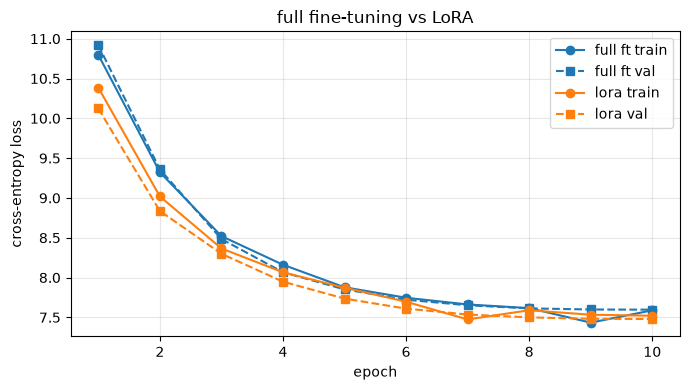

In [19]:
LORA_LR = 1e-3  # LoRA tolerates (and needs) a higher lr than full fine-tuning

# Two groups. AdamW decays every parameter that has a gradient, and the masked embedding's
# gradient is zero rather than absent -- so in the default group all 50,257 pretrained rows
# would shrink a little each step, and Task IV would measure weight decay, not forgetting.
# param_groups already puts token_emb and head in the no-decay group, which is what the
# masked rows need: AdamW decays whatever has a gradient, and a masked gradient is zero
# rather than absent, so in the default group every pretrained row would drift downward.
opt = AdamW(param_groups(lora_model), lr=LORA_LR)
lora_trainer = Trainer(
    model=lora_model,
    train_data_loader=sft_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt,
    scheduler=cosine_with_warmup(opt, FT_STEPS),
    device=device,
    save_dir="./checkpoints/tp2_lora",
    save_every_n=500,
)

history_lora = run_training(lora_trainer, epochs=FT_EPOCHS)
plot_losses({"full ft": history_full, "lora": history_lora}, title="full fine-tuning vs LoRA")

In [20]:
acc_lora_train, acc_lora = evaluate_both(lora_model, "LoRA")

### LoRA
  -- exact match, training examples --
   who_said=2.4% | reverse=0.0% | overall=0.7%
  -- exact match, held-out examples --
   XX  who_said: 'LADY'                                 want 'QUEEN MARGARET'
   XX   reverse: 's'                                    want 'nierehw'
   XX   reverse: 's'                                    want 'sedivorp'
   XX   reverse: 's'                                    want 'deyd'
   who_said=1.9% | reverse=0.0% | overall=0.7%
  gap: +0.0%
  -- continue (generative) --
   answer loss 5.411 | prompt-conditioned 66.7%   (50% = ignoring the prompt)
   ask  'continue:  here you sty me\nIn this hard rock, whiles'
   got  '\nAnd,\nAnd the<|assistant|>'
   true " you do keep from me\nThe rest o' the island"
   ask  'go on:  for the mischance of\nthe hour, if it so'
   got  ',\nAnd,\nAnd the'
   true ' hap. Cheerly, good hearts! Out\n'
   ask  'what comes next: , bountiful Fortune,\nNow my dear lady, hath'
   got  '\nAnd,\nAnd, and the<|assistant|>'
   tr

# Task IV — catastrophic forgetting

Fine-tuning moved the weights. Did it break what the model already knew?

Measure cross-entropy on the **original Shakespeare validation set** for all three
models (base, full fine-tuning, LoRA) and generate a Shakespeare continuation from
each. Note that this evaluation uses no template and no special tokens — it is exactly
the pretraining objective.

In [31]:
@torch.no_grad()
def shakespeare_loss(model) -> float:
    """
    Mean cross-entropy of `model` on shakespeare_val_loader.

    Hint: plain CrossEntropyLoss (no ignore_index -- every token counts here),
    logits.view(B * T, C) against y.view(B * T).
    """
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    dev = next(model.parameters()).device

    total = 0.0
    for x, y in shakespeare_val_loader:
        x, y = x.to(dev), y.to(dev)
        logits = model(x)
        B, T, C = logits.shape
        total += loss_fn(logits.view(B * T, C), y.view(B * T)).item()

    # every batch has the same size (drop_last=True), so the mean of batch means is the token mean
    return total / len(shakespeare_val_loader)


for name, m in (("base", base_model), ("full ft", full_ft_model), ("lora", lora_model)):
    print(f"{name:>8}: {shakespeare_loss(m):.4f}")

# A continuation from each model, with no template. Three prompts of 16 validation tokens.
# Each prompt gets its own seed, shared by the three models, so within a prompt the only
# difference is the weights.
for seed, start in enumerate((split, split + 1000, split + 2000)):
    prompt = tokenizer.decode(data[start:start + 16].tolist())
    print(f"\nprompt: {prompt!r}")
    for name, m in (("base", base_model), ("full ft", full_ft_model), ("lora", lora_model)):
        torch.manual_seed(seed)
        out = generate(m, tokenizer, prompt, max_new_tokens=30)
        print(f"{name:>8}: {out[len(prompt):]!r}")

    base: 5.5176
 full ft: 5.3474
    lora: 5.1899

prompt: ' collected them by tribes?\n\nAEdile:\nI have.\n'
    base: ' loves is, must, nob.\n\nFirst Citizen:\nYetFollowing fromIA: togetherield breath cure him wars.\ncos mar followers,'
 full ft: " loves!<|end|>MENENIUS:\nWe pledge withrecar<|end|><|end|><|end|><|end|> togethericip<|end|><|end|><|end|> wars'did to that dear angel"
    lora: " loves!\nMENENIUS:\nWe pledge withsed\nThough from hisan togethericip breath<|assistant|>ht wars'd'd to that dear angel"

prompt: '\n\nSICINIUS:\nPeace!\nWe need not put'
    base: " by of which, good, myoke-- gulf her, as' theARTwhich? their an highest meIn world who thy fought to or Here"
 full ft: " by of which, good, my I crept labour her, as to thede very black their an'd me then say in thisway to I<|assistant|>"
    lora: ' by of the, good good my I crept the her, as to thede cannot? their andefault me n say in thy in<|assistant|> or<|assistant|>'

prompt: " alike\nShow'd mastership in flo

## Questions

No extra training for any of these.

1. Rank the three models by Shakespeare loss and by the instruction metrics. Is there a
   trade-off, and does LoRA sit where you expected?
2. Explain *mechanically* why constraining the update limits forgetting — what can full
   fine-tuning do to `W` that LoRA cannot? If LoRA nonetheless matched full fine-tuning
   here, what would that say about the intrinsic rank of this adaptation, and when would
   that stop being true?
3. You unfroze something beyond the adapters for LoRA to work at all. What, why was it
   unavoidable, and what stopped it from swallowing the parameter savings whole?

---

1. By Shakespeare loss LoRA is best (5.19), then full fine-tuning (5.35), then the base model (5.52). By the instruction metrics full fine-tuning wins `who_said`, LoRA wins continue, and the base model scores 0% exact match on both `who_said` and `reverse`. So there's no trade-off between forgetting and learning here, both fine-tunes got better at Shakespeare. The base model only saw 30k tokens, and the fine-tune is mostly more Shakespeare, since 25% of L1 is replay and the continue answers come from the whole corpus. There is also a leak. The Shakespeare validation slice is tokens 27,580 to 30,645, and the training `continue` examples are cut from the first 304,222 tokens of the corpus, so both fine-tunes saw the validation text as prompts and answers for 10 epochs. Part of the drop below the base model comes from that and not from learning Shakespeare better. The trade-off is between the two fine-tunes. I expected LoRA to forget less and learn less than full fine-tuning, and that's only half right, it keeps more of the language model and loses `who_said`, but it's slightly better on continue. The forgetting that does show up is in the samples. Without a template, across the three prompts full fine-tuning inserts 20 chat tokens, almost all `<|end|>`, and LoRA 6, half `<|assistant|>` and half `<|end|>`. Both learned to emit chat tokens in plain text, which the loss barely notices.

2. Full fine-tuning can change every weight in any direction, every matrix at full rank plus the MLP, the layer norms and the position embeddings. LoRA can only add (α/r)BA to the fused query/key/value projection and the output projection of each layer, a rank 8 update in a 64 dimensional space, and everything else stays frozen except the vocabulary rows from question 3. Most directions of each W can't move, so most of what the model computed before stays as it was. LoRA matched full fine-tuning on continue, which suggests that adaptation is low rank, it's the pretraining objective plus learning the template and when to stop. I can't fully separate it though, part of it could also live in the 13,606 unfrozen rows, which have no rank limit. The learning rate is different too. LoRA trained at 1e-3 and full fine-tuning at 3e-4, and almost everything LoRA can move is those rows (6,144 adapter parameters against about 1.74M in rows). Question 6 showed the learning rate is what moves these results most, so LoRA's better Shakespeare loss may come from a faster rate on the vocabulary and not from the low-rank constraint. `who_said` shows where that stops being true. It needs a new mapping from a line to a name, and LoRA got 1.9% against 15.1%. The more the new task differs from what pretraining already computes, the more rank the update needs.

3. The embedding and output head rows of the SFT vocabulary. It was unavoidable because the four template tokens were added by `resize_token_embeddings` with random rows, and a frozen embedding gets no gradient, so the model could never learn to emit `<|end|>`. The same applies to answer tokens TP-1 never trained, since its pretraining only touched 3,558 rows. What stopped it from taking over was the gradient mask. `requires_grad` is on for the whole matrices, which is why `count_parameters` reports 98.44%, but only the 13,606 SFT rows get a non-zero gradient, so 26.72% can actually move. Those rows also sit in the no-decay group, so the masked rows don't shrink. Even so, 26.72% is a lot next to the adapters themselves. Only unfreezing the 4 template rows would cost 0.10%.

# the optional task — was pretraining worth anything?

Everything above assumes the pretrained model was a useful starting point. Test it.

Train a **randomly initialised** TinyGPT of the same size on the instruction data alone,
with the same schedule, and compare the loss curves and the accuracy against the
fine-tuned model.

Then answer: whatever gap you find, is it about *knowledge* (the model already knows the
alphabet and which letters follow which) or about *optimisation* (the pretrained weights
are simply in a better basin)? Propose an experiment that would separate the two.

from scratch: 6,535,552 parameters | 6,535,552 trainable (100.00%)
mixed precision: on (bfloat16)


val_loss 9.09113: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 95.41it/s]


epoch 1/10 | train 9.2243 | val 9.1495


val_loss 7.78416: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 95.35it/s]


epoch 2/10 | train 7.7686 | val 7.9688


...

epoch 8/10 | train 6.5097 | val 6.7406


val_loss 6.31443: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 97.15it/s]


epoch 9/10 | train 6.4945 | val 6.7284


val_loss 6.31456: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 51/51 [00:00<00:00, 95.88it/s]


epoch 10/10 | train 6.4378 | val 6.7287


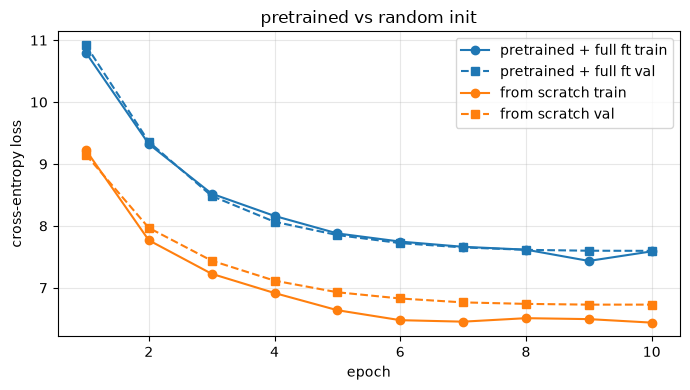

### from scratch
  -- exact match, training examples --
   who_said=4.8% | reverse=0.0% | overall=1.3%
  -- exact match, held-out examples --
   XX  who_said: 'DUKE VINCENTIO'                       want 'QUEEN MARGARET'
   XX   reverse: 'gnit'                                 want 'nierehw'
   XX   reverse: 'gnit'                                 want 'sedivorp'
   XX   reverse: 'gnit'                                 want 'deyd'
   who_said=15.1% | reverse=0.0% | overall=5.3%
  gap: -4.0%
  -- continue (generative) --
   answer loss 5.023 | prompt-conditioned 65.0%   (50% = ignoring the prompt)
   ask  'continue:  here you sty me\nIn this hard rock, whiles'
   got  ",\nAnd I'll the king, and,\nAnd"
   true " you do keep from me\nThe rest o' the island"
   ask  'go on:  for the mischance of\nthe hour, if it so'
   got  ",\nAnd I'll the king,\nAnd I'll"
   true ' hap. Cheerly, good hearts! Out\n'
   ask  'what comes next: , bountiful Fortune,\nNow my dear lady, hath'
   got  ",\nAnd I'll t

In [34]:
# Same architecture and vocabulary as the fine-tuned model, but random weights.
torch.manual_seed(1337)
scratch_model = TinyGPT(config).to(device)
scratch_model.resize_token_embeddings(len(tokenizer))
describe(scratch_model, "from scratch")

# Instruction data alone: the packed SFT blocks without the Shakespeare replay.
scratch_train_loader = DataLoader(sft_train, batch_size=config.batch_size, shuffle=True,
                                  drop_last=True, num_workers=NUM_WORKERS)
scratch_steps = FT_EPOCHS * len(scratch_train_loader)

# Same schedule as Task II: same epochs, learning rate, warmup and cosine decay.
opt_scratch = AdamW(param_groups(scratch_model), lr=FT_LR)
scratch_trainer = Trainer(
    model=scratch_model,
    train_data_loader=scratch_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt_scratch,
    scheduler=cosine_with_warmup(opt_scratch, scratch_steps),
    device=device,
    save_dir="./checkpoints/tp2_scratch",
    save_every_n=500,
)

history_scratch = run_training(scratch_trainer, epochs=FT_EPOCHS)
plot_losses({"pretrained + full ft": history_full, "from scratch": history_scratch},
            title="pretrained vs random init")
acc_scratch_train, acc_scratch = evaluate_both(scratch_model, "from scratch")

### Answer

With the same schedule pretraining bought nothing. The random model ended at an instruction validation loss of 6.73 against 7.60, reached 65.0% prompt-conditioned on `continue` against 60.0%, and tied on `who_said` at 15.1%. It was already ahead after the first epoch, 9.15 against 10.92.

I think the gap is about optimisation, not knowledge. TP-1 pretraining only touched 3,558 vocabulary rows while the SFT data uses 13,606, so at least 10,048 of the tokens in the SFT data were never a target in pretraining. The softmax pushes down every token that isn't the target, so the pretrained model most likely starts out treating those tokens as almost impossible, which fits it starting behind after the first epoch, and at 3e-4 the fine-tune spends its budget undoing that. The random model has nothing to undo. The 10x learning rate run from Task II reached 6.03, below the random model, which suggests the pretrained start is slow rather than stuck. The random model wasn't run at that learning rate though, so it isn't a fair comparison.

To separate the two, I would keep the pretrained weights but shuffle the values inside each matrix. That keeps the scale of every layer and destroys what it learned. If the shuffled model trains like the pretrained one, the difference comes from where the weights start (optimisation). If it trains like the random one, the pretrained model was using what it knew. Both should also run at the same tuned learning rate, so the schedule doesn't decide the result.

# Task V — talk to it

Everything above is measurement. This is the whole inference path: apply the template,
sample a reply, stop at `<|end|>`.

You already wrote most of it. TP-1 Task I gave you `generateV2`, with temperature, top-k,
top-p and the KV-cache. Port it into `chat()` — three things are missing:

| gap | what to add | why it matters |
|---|---|---|
| no stop condition | break when the sampled token is `END_ID` | TP-1 always ran to `max_new_tokens`; a chat model decides when it is done |
| returns prompt + completion | return the reply only | a reply is the answer, not an echo of the question |
| no logit suppression | set the `<\|user\|>`, `<\|assistant\|>`, `<\|pad\|>` logits to `-inf` | otherwise it samples chat scaffolding into the middle of a reply |

Two notes. TP-1 typed the tokenizer argument as `CharTokenizer`, but the HuggingFace one
duck-types on `.encode`/`.decode`, so it drops in unchanged. And **sample, do not decode
greedily** — greedy is right for scoring because it is deterministic, but it loops badly
on a model this small (`and the people, and the people`).

In [32]:
@torch.no_grad()
def chat(model, message: str, temperature: float = 0.8, top_p: float = 0.9,
         max_new_tokens: int = 24, seed: Optional[int] = None) -> str:
    """
    One turn: wrap `message` in the chat template, sample a reply, stop at <|end|>.

    The sampling (temperature, then top-p, with the KV-cache) is TP-1's `generateV2`.
    The three additions for chat are marked below.
    """
    if seed is not None:
        torch.manual_seed(seed)

    model.eval()
    dev = next(model.parameters()).device
    block_size = model.config.block_size

    prompt = f"{USER}{message}{ASSISTANT}"
    idx = torch.tensor(tokenizer.encode(prompt), dtype=torch.long, device=dev)[None, :]
    scaffolding_ids = tokenizer.convert_tokens_to_ids([USER, ASSISTANT, PAD])

    reply_ids = []
    kv_cache = None
    for _ in range(max_new_tokens):
        if kv_cache is None:
            idx_cond = idx[:, -block_size:]
        else:
            idx_cond = idx[:, -1:]

        logits, kv_cache = model(idx_cond, kv_cache=kv_cache, use_cache=True)
        kv_cache = trim_kv_cache(kv_cache, block_size - 1)
        logits = logits[:, -1, :]                                   # (B, V)

        # Addition 1: the chat scaffolding can never be sampled inside a reply
        logits[:, scaffolding_ids] = float("-inf")

        logits = logits / temperature
        if top_p is not None:
            sorted_logits, sorted_idx = torch.sort(logits, descending=True, dim=-1)
            sorted_probs = F.softmax(sorted_logits, dim=-1)
            # Use the mass *before* each token, so the token that crosses p is kept
            # and the most likely token always survives.
            mass_before = torch.cumsum(sorted_probs, dim=-1) - sorted_probs
            sorted_logits = sorted_logits.masked_fill(mass_before >= top_p, float("-inf"))
            logits = torch.full_like(logits, float("-inf")).scatter(-1, sorted_idx, sorted_logits)

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        # Addition 2: the model decides when the reply is over
        if next_token.item() == END_ID:
            break

        reply_ids.append(next_token.item())
        idx = torch.cat((idx, next_token), dim=1)

    # Addition 3: return the reply only, not the prompt
    return tokenizer.decode(reply_ids)


for msg in ("continue: To be, or not to be,",
            "go on: Friends, Romans, countrymen,",
            "finish this: First Citizen:\nBefore we proceed",
            "who said: Now is the winter of our discontent",
            "who said: O Romeo, Romeo, wherefore art thou Romeo?",
            "reverse: sword",
            "reverse: citizen"):
    print(f"> {msg}")
    for name, m in (("full ft", full_ft_model), ("lora", lora_model)):
        print(f"  {name:>7}: {chat(m, msg, seed=0)!r}")
    print()

> continue: To be, or not to be,
  full ft: '.\n\nMENENIUS:\nWe, with,\nWhich from'
     lora: '.\n\nMyOLADY:\nO, be,\nMy from his'

> go on: Friends, Romans, countrymen,
  full ft: '.\n\nMENENIUS:\nWe, with,\nWhich from'
     lora: '.\n\nMENENIUS:\nO, be,\nMy from his'

> finish this: First Citizen:
Before we proceed
  full ft: 'ou!'
     lora: 'ou!\nFor, for.\nFirst Citizen:\nWhat you?\n'

> who said: Now is the winter of our discontent
  full ft: 'QUEEN ELIZABETH'
     lora: 'BUCKINGBRUTUS'

> who said: O Romeo, Romeo, wherefore art thou Romeo?
  full ft: 'KING RICHARD III'
     lora: 'KING RICHARD III'

> reverse: sword
  full ft: 'oure'
     lora: 'oure'

> reverse: citizen
  full ft: 'ylre'
     lora: 'ylre'



# Task VI — what does it attend to?

Task II showed that the model routes on the instruction: the same input under `continue`
and under `reverse` produces different answers. This asks *how*.

At the `<|assistant|>` position — the moment before it commits to a first answer token —
which tokens does attention actually weight? The task marker (`continue`, `who_said`), or
the content that follows it?

You visualised attention in TP-1 Task IV. `tinygpt.visualize_attention` still works, with
one catch: it calls `tokenizer.itos[i]`, which a HuggingFace tokenizer does not have. Fix
that line, or print the weights as a table.

`model(idx, return_weights=True)` returns `(logits, weights)`, where each layer's entry is
shaped `(n_head, B, T, T_k)`. Average over heads and take the last query row.

Report what the answer position looks at for one example of each task, and connect it to
the accuracy you measured in Task II.

In [33]:
@torch.no_grad()
def attention_at_answer(model, message: str, layer: int = -1, top: int = 6) -> None:
    """
    Print the tokens the <|assistant|> position attends to most, for one prompt.

    Hint: mean over heads of weights[layer][:, 0, -1, :].
    """
    model.eval()
    dev = next(model.parameters()).device

    prompt = f"{USER}{message}{ASSISTANT}"
    ids = tokenizer.encode(prompt)[-model.config.block_size:]
    idx = torch.tensor(ids, dtype=torch.long, device=dev)[None, :]

    _, weights = model(idx, return_weights=True)

    # weights[layer] is (n_head, B, T, T_k). The last query row is the <|assistant|>
    # position, the moment before the first answer token.
    at_answer = weights[layer][:, 0, -1, :].mean(dim=0)              # (T_k,)
    tokens = [tokenizer.decode([i]) for i in ids]

    top_weights, top_positions = at_answer.topk(min(top, len(ids)))
    print(f"{message!r}  (layer {layer})")
    for w, pos in zip(top_weights.tolist(), top_positions.tolist()):
        print(f"   {w:.3f}  position {pos:>2}  {tokens[pos]!r}")
    print()


# Both layers: the first one is where the task marker gets read.
for m in ("continue: To be, or not to be,", "go on: Friends, Romans, countrymen,",
          "what comes next: My lord, I",
          "who said: Now is the winter", "who said: O Romeo, Romeo, wherefore",
          "who said: Before we proceed any further",
          "reverse: sword", "reverse: hamlet", "reverse: citizen"):
    for layer in range(config.n_layer):
        attention_at_answer(full_ft_model, m, layer=layer)

'continue: To be, or not to be,'  (layer 0)
   0.254  position 11  '<|assistant|>'
   0.220  position  0  '<|user|>'
   0.194  position 10  ','
   0.095  position  2  ':'
   0.091  position  1  'continue'
   0.053  position  6  ' or'

'continue: To be, or not to be,'  (layer 1)
   0.211  position  1  'continue'
   0.178  position 11  '<|assistant|>'
   0.089  position  6  ' or'
   0.083  position  9  ' be'
   0.080  position  5  ','
   0.080  position 10  ','

'go on: Friends, Romans, countrymen,'  (layer 0)
   0.196  position 11  '<|assistant|>'
   0.192  position 10  ','
   0.156  position  0  '<|user|>'
   0.096  position  8  ' country'
   0.079  position  2  ' on'
   0.069  position  1  'go'

'go on: Friends, Romans, countrymen,'  (layer 1)
   0.239  position  1  'go'
   0.211  position 11  '<|assistant|>'
   0.103  position 10  ','
   0.096  position  5  ','
   0.090  position  9  'men'
   0.087  position  7  ','

'what comes next: My lord, I'  (layer 0)
   0.306  position  8  ' I

### Answer

At the `<|assistant|>` position the first layer reads the instruction and the second layer reads what it needs from the prompt. In layer 0 the strongest weight for `reverse` is on `reverse` (0.376) and for `who_said` on `said` (0.302), so the task marker is picked up early. `continue` is different, in layer 1 its top token is `continue` (0.211) followed by `<|assistant|>` and then the content (` or`, ` be`, `,`). In layer 1 `reverse` puts most of its weight on `<|assistant|>`, `:` and `<|user|>` (0.785 together) and 0.176 on ` sword`, and `who_said` also has the structural tokens on top with ` the` and ` winter` below. The two extra prompts of each task show the same pattern. In layer 0 every `who_said` prompt peaks on `said` and every `reverse` prompt on `reverse`, in layer 1 every `continue` prompt peaks on its first instruction word (`continue`, `go`, `what`), and the word to reverse never gets more than 0.176.

This matches Task II. `continue` spreads attention over the prefix and it's the task that works (60.0% prompt-conditioned). `reverse` does look at ` sword`, so the word reaches the answer position, but the model can't turn a whole-word token into reversed pieces and it scores 0%. `who_said` reads the marker in layer 0 but spends most of layer 1 on structure rather than on the line, which fits a 15.1% that beats the 3.5% baseline without being good.

# Is the model still healthy?

Accuracy is not the only thing worth measuring. A model that scores 0% but emits
well-formed, terminating replies is still a working generator; one that emits `!` for ever
is not, whatever its loss says.

Two properties: replies **stop on their own** at `<|end|>`, and the model is **still a
language model** — pretraining loss near the base model's.

In [29]:
@torch.no_grad()
def generation_health(model, name: str, n: int = 60) -> None:
    """Does it terminate, and is it still a language model? Not accuracy."""
    lengths = [len(tokenizer.encode(generate_until(model, format_example(ex)[0])))
               for ex in val_examples[:n]]
    stopped = sum(1 for L in lengths if L < 24)      # 24 is generate_until's cap
    print(f"{name:>9} | {100 * stopped / n:>9.1f}% | {sum(lengths) / n:>9.1f} | "
          f"{shakespeare_loss(model):>10.3f}")


print(f"{'model':>9} | {'terminates':>10} | {'mean len':>9} | {'lm loss':>10}")
print("-" * 48)
for nm, m in (("base", base_model), ("full ft", full_ft_model), ("lora", lora_model)):
    generation_health(m, nm)

ex = next(e for e in val_examples if e[0] == "continue")
print(f"\nsample response to {format_example(ex)[0]!r}:")
print(f"  {generate_until(full_ft_model, format_example(ex)[0], max_new_tokens=20)!r}")
print("\nHealthy = terminates on its own AND keeps lm loss near the base model's.")

    model | terminates |  mean len |    lm loss
------------------------------------------------
     base |       0.0% |      24.0 |      5.518
  full ft |     100.0% |       4.3 |      5.347
     lora |     100.0% |       4.4 |      5.190

sample response to '<|user|>continue:  here you sty me\nIn this hard rock, whiles<|assistant|>':
  '\nAnd the'

Healthy = terminates on its own AND keeps lm loss near the base model's.


# ⚠️ Keep your checkpoints

`Trainer` writes `checkpoint_final.pt` at the end of every epoch, so a completed run has
already left these on your machine:

```
./checkpoints/tp2_full_ft/checkpoint_final.pt
./checkpoints/tp2_lora/checkpoint_final.pt
```

**You do not hand these in — just do not delete them.** TP-3 continues from the model you
fine-tuned here rather than training a new one. If you clear `./checkpoints/` you will have
to run Task II and Task III again, which is most of the runtime of this notebook.

Run the cell below before you finish, and make sure both lines say `ok`.

In [30]:
import os

print("files TP-3 will continue from -- keep these locally:\n")
missing = 0
for p in ("./checkpoints/tp2_full_ft/checkpoint_final.pt",
          "./checkpoints/tp2_lora/checkpoint_final.pt"):
    exists = os.path.exists(p)
    missing += not exists
    size = f"{os.path.getsize(p) / 1e6:>6.0f} MB" if exists else "   MISSING"
    print(f"  [{'ok' if exists else '!!'}] {p:<46} {size}")

print("\nkeep this directory -- TP-3 continues from it rather than retraining."
      if not missing else
      "\nrun Task II and Task III to completion before moving on to TP-3.")


files TP-3 will continue from -- keep these locally:

  [ok] ./checkpoints/tp2_full_ft/checkpoint_final.pt      78 MB
  [ok] ./checkpoints/tp2_lora/checkpoint_final.pt         78 MB

keep this directory -- TP-3 continues from it rather than retraining.


# Conclusions

- Prompt masking with the GPT-1 objective (L2 plus 0.5 L1) and a chat template turned the TP-1 model into one that answers in the template and stops on its own, 100% termination against 0% for the base model. What it learns depends on how close the task is to pretraining. `continue` works, `who_said` beats its baseline, and `reverse` fails because BPE hides the characters.
- LoRA trained 6,144 adapter parameters plus the masked SFT vocabulary rows, 26.72% of the model against the 98.44% that `count_parameters` reports. It matched full fine-tuning on `continue` and ended with the best Shakespeare loss (5.19), but fell to 1.9% on `who_said`, the task that needs a new mapping.
- At this scale pretraining was not a useful start with the Task II schedule. A random model trained on the instructions alone did as well or better, and neither fine-tune showed forgetting in the loss, although the validation text was also inside the `continue` training data. Both did leak chat tokens into plain text, which only shows up in the samples.

# Congratulations! 🎉

Across two notebooks you pretrained a GPT, implemented the decoding strategies that
turn it into a text generator, made it sparse with a Mixture of Experts, and aligned it
to a task with both full fine-tuning and LoRA.

That is the whole modern LLM pipeline, at a scale you can read end to end.